# Hierarchical clustering model
  
The model analyses the spending behavior of mall customers and groups them based on similarity using hierarchical clustering.

In [149]:
# importing packages 
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

#loading dataset
df = pd.read_csv("Mall_Customers.csv")

In [150]:
#highe lever view of the data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [151]:
df.isnull().sum()
# it shows none are missing

CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [152]:
df.head()

,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [153]:
#feature selection
#only going to use numerical
x = df[['Annual Income (k$)','Spending Score (1-100)']]

In [154]:
x.describe()

,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000
mean,60.560000,50.200000
std,26.264721,25.823522
min,15.000000,1.000000
25%,41.500000,34.750000
50%,61.500000,50.000000
75%,78.000000,73.000000
max,137.000000,99.000000


In [155]:
x.head()

,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


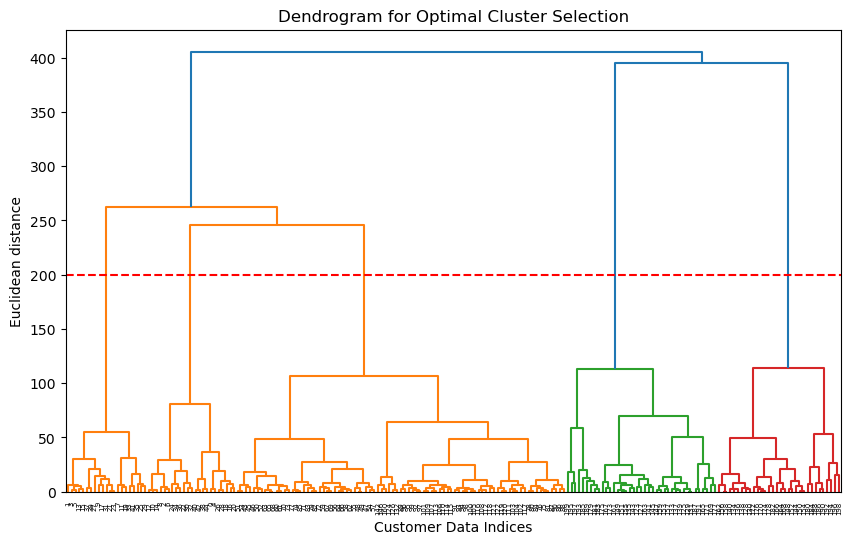

In [156]:
#creating the dendrogram
import scipy.cluster.hierarchy as sch

plt.figure(figsize=(10,6))
dendrogram = sch.dendrogram(sch.linkage(x,method='ward'))
plt.title('Dendrogram for Optimal Cluster Selection')
plt.xlabel('Customer Data Indices')
plt.ylabel('Euclidean distance')
plt.axhline(y=200, color='r',linestyle='--')
plt.show()

# therefore k=3

In [157]:
from sklearn.cluster import AgglomerativeClustering

hc = AgglomerativeClustering(
n_clusters = 5,
metric = 'euclidean',
linkage = 'ward',
)

y_hc = hc.fit_predict(x)

In [158]:
#Evalueation: Quantitative evaluation
from sklearn.metrics import silhouette_score

score = silhouette_score(x,y_hc)
print(f"Silhouette score for model: {score:.4f}")

Silhouette score for model: 0.5530


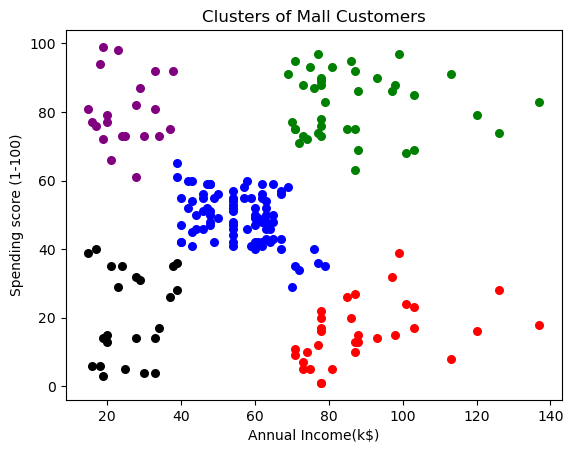

In [ ]:
#Evaluation: Qualitatie evaluation(Pictures)
x = x.values
plt.title('Clusters of Mall Customers')
plt.xlabel('Annual Income(k$)')
plt.ylabel('Spending score (1-100)')

plt.scatter(x[y_hc == 0,0],x[y_hc == 0,1],s=30,c='red',label='Careful(High Income, Low Spenders)')
plt.scatter(x[y_hc == 1,0],x[y_hc == 1,1],s=30,c='blue',label='Standard(Avg Income, Avg spenders)')
plt.scatter(x[y_hc ==2,0],x[y_hc == 2,1], s=30,c='green',label='(High Income,High spenders)')
plt.scatter(x[y_hc == 3,0],x[y_hc==3,1],s=30,c='purple',label='(Low Income, High spenders)')
plt.scatter(x[y_hc == 4,0],x[y_hc==4,1],s=30,c='black',label='(Low Income, Low spenders)')

plt.show()